# T011 · 在线 API Web 服务查询

**说明：**本教程属于 TeachOpenCADD 项目。该平台旨在教授领域专属技能，并提供可作为研究项目起点的流程模板。

作者：

- Jaime Rodríguez-Guerra，2020–2021，[Volkamer 实验室，Charité](https://volkamerlab.org/)
- Dominique Sydow，2021，[Volkamer 实验室，Charité](https://volkamerlab.org/)
- David Schaller，2021，[Volkamer 实验室，Charité](https://volkamerlab.org/)

## 本教程的目标

本 notebook 将介绍如何在药物设计场景中使用 Python 以编程方式访问在线 Web 服务。完成本教程后，你将熟悉 REST 服务和 Web 抓取。

### 理论内容

* 从服务器端视角理解数据访问

### 实践内容

* 下载静态文件
* 访问动态生成的内容
* 编程接口
* 文档解析
* 浏览器远程控制

### 参考资料

本指南侧重实践，为了清晰起见，省略了一些技术定义。不过，要充分理解后台发生的事情，也需要掌握一些基本术语。

* [客户端-服务器模型](https://en.wikipedia.org/wiki/Client%E2%80%93server_model)
* [Web API](https://en.wikipedia.org/wiki/Web_API)
* [查询字符串](https://en.wikipedia.org/wiki/Query_string)
* [REST](https://en.wikipedia.org/wiki/Representational_state_transfer)
* [JSON](https://en.wikipedia.org/wiki/JSON)
* [Swagger / OpenAPI](https://en.wikipedia.org/wiki/Swagger_(software))
* [HTTP 概览](https://developer.mozilla.org/en-US/docs/Web/HTTP/Overview)

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install teachopencadd --no-deps -q
    !teachopencadd -d 11
    %pip uninstall teachopencadd -y -q
    %pip install -qr requirements.txt

## 理论

互联网由彼此连接并交换数据的计算机构成。可以把操作理解为：向服务器发送带有特定参数的查询，以获取指定数据。服务器返回的数据通常有以下几种来源：

- **A**. 服务器直接提供数据，因为它只是一个文件仓库。例如，你可以从服务器[下载 ChEMBL 数据库转储文件](ftp://ftp.ebi.ac.uk/pub/databases/chembl/ChEMBLdb/latest/)。
- **B**. 服务器从数据库中检索数据，并按特定方式格式化。浏览器显示的结果可能是：
    - **B1**. 由服务器预先处理，例如访问任意一篇 [Wikipedia 文章](https://en.wikipedia.org/wiki/Drug_design)时看到的 HTML 页面。
    - **B2**. 在你使用网站时，由客户端（浏览器）动态生成，例如 Twitter、Facebook 或任何现代 _Web 应用_。
- **C**. 由服务器端运行一个或多个程序计算得到，例如使用 [Protoss](https://proteins.plus/help/tutorial)估计蛋白质-配体复合物的质子化状态。

> 从某种角度看，**C** 是 **B1** 的一种特殊情形。变化的只是服务器上执行的任务：由数据库查询和 HTML 渲染，变成处理查询并以特定领域格式返回数据的计算。

还可以根据返回数据的_格式_对在线服务分类。浏览器中多数网页使用 HTML，通常以方便人阅读的方式呈现数据。不过，有些服务器会将数据组织成便于_机器_读取的格式。由于这类数据遵循一套一致且易于写入程序的规则，因此可以可靠地进行处理。用于此类处理的程序通常称为_解析器_。HTML 可以通过标记来帮助可靠地提取数据，但它本身并非为此目的设计。因此，我们通常优先使用提供 JSON、CSV 或 XML 等机器可读格式的服务。

实际上，这两种数据呈现方式应该和谐共存。现代 Web 架构力求将数据检索与面向最终用户的呈现分开。一种常见实现是使用编程接口端点返回机器可读的 JSON 数据，再由面向用户的 Web 应用读取这些数据。后者负责渲染 HTML，渲染可以在服务器上完成（选项 **B1**），也可以在用户的浏览器中完成（选项 **B2**）。遗憾的是，编程接口（API）不像面向用户的应用那样一定公开，有时仅供服务器内部使用。

接下来，我们将介绍如何使用 Python 和一些库，充分利用不同类型的在线服务！

## 实践

In [2]:
from pathlib import Path

HERE = Path(_dh[-1])
DATA = HERE / "data"
TMPDATA = DATA / "_tmp"  # this dir is gitignored
TMPDATA.mkdir(parents=True, exist_ok=True)

### 下载静态文件

在这种情况下，Web 服务器托管着可供你下载并直接使用的文件。你只需通过正确的地址或 URL（统一资源定位符）_查询_服务器即可。你平时浏览互联网时一直在这样做，也可以用 Python 完成同样的操作！

例如，我们来获取这个来自 GitHub 的[激酶相关 CSV 数据集](https://github.com/openkinome/kinodata/blob/master/data/KinHubKinaseList.csv)，其中列出了激酶及其标识符。

> 提示：如果要下载 GitHub 上托管的文件，请使用 `Raw` 按钮获取可下载的 URL！
>
> 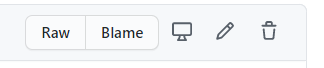

Python 提供了用于处理 HTTP 查询的库（`urllib`），不过很多人更喜欢使用第三方库 `requests`，因为它用起来简单得多。

In [3]:
import requests

url = "https://raw.githubusercontent.com/openkinome/kinodata/master/data/KinHubKinaseList.csv"
response = requests.get(url)
response.raise_for_status()
response

# NBVAL_CHECK_OUTPUT

<Response [200]>

调用 `requests.get(...)` 后会得到一个 `Response` 对象。它_不是_你要下载的文件本身，而是一个封装了 HTTP 查询及服务器_响应_的对象。在检查内容之前，我们总是先调用 `.raise_for_status()`；如果服务器表示请求无法完成，该方法就会引发异常。服务器如何表示？使用 [HTTP 状态码](https://en.wikipedia.org/wiki/List_of_HTTP_status_codes)，即一个三位数。状态码有很多，常见的包括：

* 200：一切正常！
* 404：找不到文件。
* 500：服务器错误。

如果响应的状态码不是 200，`.raise_for_status()` 就会报错。因此，最好在_每次_查询后都调用它！

下面演示一个错误的 URL：它有误，因为该地址没有 **TXT** 文件，只有 **CSV** 文件。

In [4]:
# NBVAL_RAISES_EXCEPTION
bad_url = "https://raw.githubusercontent.com/openkinome/kinodata/master/data/KinHubKinaseList.txt"
bad_response = requests.get(bad_url)
bad_response.raise_for_status()
bad_response

HTTPError: 404 Client Error: Not Found for url: https://raw.githubusercontent.com/openkinome/kinodata/master/data/KinHubKinaseList.txt

好，现在来读取 CSV 文件的内容！根据你要处理的内容，可以使用以下属性之一：

* `response.content`：服务器返回的_字节_内容。
* `response.text`：如果可能，将文件内容作为字符串返回。
* `response.json()`：如果服务器返回 JSON 数据（稍后会详细介绍），该方法会解析数据并返回相应的字典。

应该使用哪一个？如果想在 Notebook 输出中显示_文本_，使用 `.text`。涉及二进制文件（图像、压缩包、PDF 等）或需要下载到磁盘的内容，则应使用 `.content`。

因为这是一个 CSV 文件，我们知道它是纯文本文件，因此可以使用常规 Python 方法处理！下面打印前 10 行：

In [5]:
print(*response.text.splitlines()[:10], sep="\n")

﻿xName,Manning Name,HGNC Name,Kinase Name,Group,Family,SubFamily,UniprotID
ABL1,ABL,ABL1,Tyrosine-protein kinase ABL1,TK,Abl,,P00519
ACK,ACK,TNK2,Activated CDC42 kinase 1,TK,Ack,,Q07912
ACTR2,ACTR2,ACVR2A,Activin receptor type-2A,TKL,STKR,STKR2,P27037
ACTR2B,ACTR2B,ACVR2B,Activin receptor type-2B,TKL,STKR,STKR2,Q13705
ADCK4,ADCK4,ADCK4,Uncharacterized aarF domain-containing protein kinase 4,Atypical,ABC1,ABC1-A,Q96D53
Trb1,Trb1,TRIB1,Tribbles homolog 1,CAMK,Trbl,,Q96RU8
BRSK2,BRSK2,BRSK2,Serine/threonine-protein kinase BRSK2,CAMK,CAMKL,BRSK,Q8IWQ3
Wnk2,Wnk2,WNK2,Serine/threonine-protein kinase WNK2,Other,WNK,,Q9Y3S1
AKT1,AKT1,AKT1,RAC-alpha serine/threonine-protein kinase,AGC,Akt,,P31749


当然，你可以使用常规 Python 语句将文件保存到磁盘。由于这里要_下载_文件，建议使用原始字节内容，而不是文本版本！也就是说，使用 `response.content`，并以字节模式打开文件（`wb` 中的 `b`）：

In [6]:
with open(TMPDATA / "kinhub.csv", "wb") as f:
    f.write(response.content)

重新打开文件，检查写入的内容。

In [7]:
# We need the encoding="utf-8-sig" to ensure correct encoding
# under all platforms
with open(TMPDATA / "kinhub.csv", encoding="utf-8-sig") as f:
    # Zip will stop iterating with the shortest iterator
    # passing `range(5)` allow us to just get five lines ;)
    for _, line in zip(range(5), f):
        print(line.rstrip())

# NBVAL_CHECK_OUTPUT

xName,Manning Name,HGNC Name,Kinase Name,Group,Family,SubFamily,UniprotID
ABL1,ABL,ABL1,Tyrosine-protein kinase ABL1,TK,Abl,,P00519
ACK,ACK,TNK2,Activated CDC42 kinase 1,TK,Ack,,Q07912
ACTR2,ACTR2,ACVR2A,Activin receptor type-2A,TKL,STKR,STKR2,P27037
ACTR2B,ACTR2B,ACVR2B,Activin receptor type-2B,TKL,STKR,STKR2,Q13705


ℹ **提示**：如果只是想下载 CSV 文件并用 Pandas 打开，可以直接把原始 URL 传给 `pandas.read_csv`。它会替你下载文件！

In [8]:
import pandas as pd

df = pd.read_csv(
    "https://raw.githubusercontent.com/openkinome/kinodata/master/data/KinHubKinaseList.csv"
)
df.head()
# NBVAL_CHECK_OUTPUT

,xName,Manning Name,HGNC Name,Kinase Name,Group,Family,SubFamily,UniprotID
0,ABL1,ABL,ABL1,Tyrosine-protein kinase ABL1,TK,Abl,NaN,P00519
1,ACK,ACK,TNK2,Activated CDC42 kinase 1,TK,Ack,NaN,Q07912
2,ACTR2,ACTR2,ACVR2A,Activin receptor type-2A,TKL,STKR,STKR2,P27037
3,ACTR2B,ACTR2B,ACVR2B,Activin receptor type-2B,TKL,STKR,STKR2,Q13705
4,ADCK4,ADCK4,ADCK4,Uncharacterized aarF domain-containing protein...,Atypical,ABC1,ABC1-A,Q96D53


关于文件下载还需注意一点：上面的方法会把整个文件下载到内存中，对于非常大的文件可能会造成问题。如果要下载很大的文件，可以使用 [streaming requests](https://requests.readthedocs.io/en/master/user/advanced/#streaming-requests) 和[原始响应](https://docs.python-requests.org/en/v1.1.0/user/quickstart/?highlight=raw%20response#raw-response-content)直接写入磁盘。举例来说，假设这个 [1MB 视频](https://archive.org/download/SlowMotionFlame/slomoflame_512kb.mp4)大到_无法放入内存_：

In [9]:
import shutil
from IPython.display import Video

response = requests.get(
    "https://archive.org/download/SlowMotionFlame/slomoflame_512kb.mp4", stream=True
)
response.raise_for_status()

with open(TMPDATA / "video.mp4", "wb") as tmp:
    for chunk in response.iter_content(chunk_size=8192):
        tmp.write(chunk)

    # Let's play the movie in Jupyter!
    # Paths passed to widgets need to be relative to notebook or they will 404 :)
    display(Video(Path(tmp.name).relative_to(HERE)))

### 访问动态生成的内容

到目前为止，我们已经能够获取远程服务器上现成的_文件_。为此，我们使用了 `requests.get` 和一个指向文件的 URL。

其实，同样的方法也适用于许多其他类型的内容！服务器如何处理这个 URL 并不重要。无论服务器只是提供磁盘上的文件，还是查询数据库并将不同部分组装成返回内容，都不会影响客户端的请求方式。

单是这个概念就非常强大，接下来你会看到具体例子。请记住：**我们只需确保请求了正确的 URL！**

现在来做点有趣的事！SARS-CoV-2 的刺突蛋白近来备受关注，我们能否使用 `requests` 从 [UniProt](https://www.uniprot.org/) 获取一些信息？它的 UniProt ID 是 `P0DTC2`。先用浏览器[查看一下](https://www.uniprot.org/uniprot/P0DTC2)，你应该会看到类似下面的页面：

![UniProt entry for SARS-CoV-2](images/uniprot-sars-cov-2.jpg)

UniProt 提供的信息之一是所列蛋白质的氨基酸序列。向下滚动，找到下面这部分：

![Sequence for SARS-CoV-2](images/uniprot-sars-cov-2-sequence.jpg)

你觉得能否只用 Python 获取_序列_？我们来试试！

要查询蛋白质，只需将它的 UniProt ID 添加到 URL 中。

In [10]:
r = requests.get("https://www.uniprot.org/uniprot/P0DTC2")
r.raise_for_status()
print(r.text[:5000])

<!doctype html><html lang="en"><head><meta charset="utf-8"/><title>UniProt</title><meta name="viewport" content="width=device-width,initial-scale=1"/><link rel="preconnect" href="https://rest.uniprot.org/"/><link rel="preconnect" href="https://fonts.googleapis.com"/><link rel="preconnect" href="https://fonts.gstatic.com" crossorigin/><meta name="theme-color" content="#00639a"/><meta property="og:logo" content="https://www.uniprot.org/android-chrome-512x512.png"/><meta property="og:title" content="UniProt"/><meta property="og:description" content="UniProt is the world's leading high-quality, comprehensive and freely accessible resource of protein sequence and functional information."/><meta property="og:image" content="https://www.uniprot.org/og-uniprot-wide-logo-1200x630.png"/><meta property="og:type" content="website"/><meta property="og:site_name" content="UniProt"/><meta property="og:image" content="https://www.uniprot.org/og-uniprot-square-logo-1200x1200.png"/><meta property="og:im

哇，这么多杂乱内容是什么？你看到的是网页的 HTML 内容！Web 开发者用这种标记语言编写网页。

有一些库可以处理 HTML 并提取实际内容（例如 `BeautifulSoup`，后文会介绍），但这里暂时用不到。幸运的是，UniProt 还提供了其他数据表示格式。

![UniProt formats](images/uniprot-sars-cov-2-formats.jpg)

有些格式更适合编程使用。如果在浏览器中点击 `Text`，页面会变成纯文本！注意，URL 也发生了变化。

* HTML 表示（默认）：https://www.uniprot.org/uniprot/P0DTC2
* 文本表示：https://www.uniprot.org/uniprot/P0DTC2.txt

只需添加 `.txt` 扩展名，就能改变数据的呈现形式。这是 UniProt 提供的一项实用功能。它看起来像是在模拟文件系统，实际上改变的是返回内容的表示格式。设计很巧妙！更重要的是，这样更便于以编程方式处理！来看一下：

In [11]:
r = requests.get("https://www.uniprot.org/uniprot/P0DTC2.txt")
r.raise_for_status()
print(r.text[:1000])

ID   SPIKE_SARS2             Reviewed;        1273 AA.
AC   P0DTC2;
DT   22-APR-2020, integrated into UniProtKB/Swiss-Prot.
DT   22-APR-2020, sequence version 1.
DT   18-JUN-2025, entry version 28.
DE   RecName: Full=Spike glycoprotein {ECO:0000255|HAMAP-Rule:MF_04099};
DE            Short=S glycoprotein {ECO:0000255|HAMAP-Rule:MF_04099};
DE   AltName: Full=E2 {ECO:0000255|HAMAP-Rule:MF_04099};
DE   AltName: Full=Peplomer protein {ECO:0000255|HAMAP-Rule:MF_04099};
DE   Contains:
DE     RecName: Full=Spike protein S1 {ECO:0000255|HAMAP-Rule:MF_04099};
DE   Contains:
DE     RecName: Full=Spike protein S2 {ECO:0000255|HAMAP-Rule:MF_04099};
DE   Contains:
DE     RecName: Full=Spike protein S2' {ECO:0000255|HAMAP-Rule:MF_04099};
DE   Flags: Precursor;
GN   Name=S {ECO:0000255|HAMAP-Rule:MF_04099}; ORFNames=2;
OS   Severe acute respiratory syndrome coronavirus 2 (2019-nCoV) (SARS-CoV-2).
OC   Viruses; Riboviria; Orthornavirae; Pisuviricota; Pisoniviricetes;
OC   Nidovirales; Cornidovirineae;

这_正是_我们在浏览器中看到的内容！对于这类任务，纯文本很方便。不过，序列位于文件末尾。要提取它，需要想办法分析每一行中的标记。注意，序列部分以 `SQ` 开始，以 `//` 结束：

```
SQ   SEQUENCE   1273 AA;  141178 MW;  B17BE6D9F1C4EA34 CRC64;
     MFVFLVLLPL VSSQCVNLTT RTQLPPAYTN SFTRGVYYPD KVFRSSVLHS TQDLFLPFFS
     NVTWFHAIHV SGTNGTKRFD NPVLPFNDGV YFASTEKSNI IRGWIFGTTL DSKTQSLLIV
     NNATNVVIKV CEFQFCNDPF LGVYYHKNNK SWMESEFRVY SSANNCTFEY VSQPFLMDLE
     GKQGNFKNLR EFVFKNIDGY FKIYSKHTPI NLVRDLPQGF SALEPLVDLP IGINITRFQT
     LLALHRSYLT PGDSSSGWTA GAAAYYVGYL QPRTFLLKYN ENGTITDAVD CALDPLSETK
     CTLKSFTVEK GIYQTSNFRV QPTESIVRFP NITNLCPFGE VFNATRFASV YAWNRKRISN
     CVADYSVLYN SASFSTFKCY GVSPTKLNDL CFTNVYADSF VIRGDEVRQI APGQTGKIAD
     YNYKLPDDFT GCVIAWNSNN LDSKVGGNYN YLYRLFRKSN LKPFERDIST EIYQAGSTPC
     NGVEGFNCYF PLQSYGFQPT NGVGYQPYRV VVLSFELLHA PATVCGPKKS TNLVKNKCVN
     FNFNGLTGTG VLTESNKKFL PFQQFGRDIA DTTDAVRDPQ TLEILDITPC SFGGVSVITP
     GTNTSNQVAV LYQDVNCTEV PVAIHADQLT PTWRVYSTGS NVFQTRAGCL IGAEHVNNSY
     ECDIPIGAGI CASYQTQTNS PRRARSVASQ SIIAYTMSLG AENSVAYSNN SIAIPTNFTI
     SVTTEILPVS MTKTSVDCTM YICGDSTECS NLLLQYGSFC TQLNRALTGI AVEQDKNTQE
     VFAQVKQIYK TPPIKDFGGF NFSQILPDPS KPSKRSFIED LLFNKVTLAD AGFIKQYGDC
     LGDIAARDLI CAQKFNGLTV LPPLLTDEMI AQYTSALLAG TITSGWTFGA GAALQIPFAM
     QMAYRFNGIG VTQNVLYENQ KLIANQFNSA IGKIQDSLSS TASALGKLQD VVNQNAQALN
     TLVKQLSSNF GAISSVLNDI LSRLDKVEAE VQIDRLITGR LQSLQTYVTQ QLIRAAEIRA
     SANLAATKMS ECVLGQSKRV DFCGKGYHLM SFPQSAPHGV VFLHVTYVPA QEKNFTTAPA
     ICHDGKAHFP REGVFVSNGT HWFVTQRNFY EPQIITTDNT FVSGNCDVVI GIVNNTVYDP
     LQPELDSFKE ELDKYFKNHT SPDVDLGDIS GINASVVNIQ KEIDRLNEVA KNLNESLIDL
     QELGKYEQYI KWPWYIWLGF IAGLIAIVMV TIMLCCMTSC CSCLKGCCSC GSCCKFDEDD
     SEPVLKGVKL HYT
//
```

因此，可以采用类似下面的处理方式：

In [12]:
sequence_block = False
lines = []
for line in r.text.splitlines():
    if line.startswith("SQ"):
        sequence_block = True
    elif line.startswith("//"):
        sequence_block = False

    if sequence_block:
        line = line.strip()  # delete spaces and newlines at the beginning and end of the line
        line = line.replace(" ", "")  # delete spaces in the middle of the line
        lines.append(line)
sequence = "".join(lines[1:])  # the first line is the metadata header
print(f"This is your sequence: {sequence}")

# NBVAL_CHECK_OUTPUT

This is your sequence: MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSSVLHSTQDLFLPFFSNVTWFHAIHVSGTNGTKRFDNPVLPFNDGVYFASTEKSNIIRGWIFGTTLDSKTQSLLIVNNATNVVIKVCEFQFCNDPFLGVYYHKNNKSWMESEFRVYSSANNCTFEYVSQPFLMDLEGKQGNFKNLREFVFKNIDGYFKIYSKHTPINLVRDLPQGFSALEPLVDLPIGINITRFQTLLALHRSYLTPGDSSSGWTAGAAAYYVGYLQPRTFLLKYNENGTITDAVDCALDPLSETKCTLKSFTVEKGIYQTSNFRVQPTESIVRFPNITNLCPFGEVFNATRFASVYAWNRKRISNCVADYSVLYNSASFSTFKCYGVSPTKLNDLCFTNVYADSFVIRGDEVRQIAPGQTGKIADYNYKLPDDFTGCVIAWNSNNLDSKVGGNYNYLYRLFRKSNLKPFERDISTEIYQAGSTPCNGVEGFNCYFPLQSYGFQPTNGVGYQPYRVVVLSFELLHAPATVCGPKKSTNLVKNKCVNFNFNGLTGTGVLTESNKKFLPFQQFGRDIADTTDAVRDPQTLEILDITPCSFGGVSVITPGTNTSNQVAVLYQDVNCTEVPVAIHADQLTPTWRVYSTGSNVFQTRAGCLIGAEHVNNSYECDIPIGAGICASYQTQTNSPRRARSVASQSIIAYTMSLGAENSVAYSNNSIAIPTNFTISVTTEILPVSMTKTSVDCTMYICGDSTECSNLLLQYGSFCTQLNRALTGIAVEQDKNTQEVFAQVKQIYKTPPIKDFGGFNFSQILPDPSKPSKRSFIEDLLFNKVTLADAGFIKQYGDCLGDIAARDLICAQKFNGLTVLPPLLTDEMIAQYTSALLAGTITSGWTFGAGAALQIPFAMQMAYRFNGIGVTQNVLYENQKLIANQFNSAIGKIQDSLSSTASALGKLQDVVNQNAQALNTLVKQLSSNFGAISSVL

大功告成！我们进行了一些处理，但确实得到了结果……不过，也应该想想有没有更简单的方法。既然 UniProt 已经提供了方便的文本表示，为什么不直接提供一个只返回指定 UniProt ID 对应序列的 URL 呢？其实它提供了！只需将 `.txt` 改成 `.fasta`：https://www.uniprot.org/uniprot/P0DTC2.fasta

In [13]:
r = requests.get("https://www.uniprot.org/uniprot/P0DTC2.fasta")
r.raise_for_status()
print(r.text)

# NBVAL_CHECK_OUTPUT

>sp|P0DTC2|SPIKE_SARS2 Spike glycoprotein OS=Severe acute respiratory syndrome coronavirus 2 OX=2697049 GN=S PE=1 SV=1
MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSSVLHSTQDLFLPFFS
NVTWFHAIHVSGTNGTKRFDNPVLPFNDGVYFASTEKSNIIRGWIFGTTLDSKTQSLLIV
NNATNVVIKVCEFQFCNDPFLGVYYHKNNKSWMESEFRVYSSANNCTFEYVSQPFLMDLE
GKQGNFKNLREFVFKNIDGYFKIYSKHTPINLVRDLPQGFSALEPLVDLPIGINITRFQT
LLALHRSYLTPGDSSSGWTAGAAAYYVGYLQPRTFLLKYNENGTITDAVDCALDPLSETK
CTLKSFTVEKGIYQTSNFRVQPTESIVRFPNITNLCPFGEVFNATRFASVYAWNRKRISN
CVADYSVLYNSASFSTFKCYGVSPTKLNDLCFTNVYADSFVIRGDEVRQIAPGQTGKIAD
YNYKLPDDFTGCVIAWNSNNLDSKVGGNYNYLYRLFRKSNLKPFERDISTEIYQAGSTPC
NGVEGFNCYFPLQSYGFQPTNGVGYQPYRVVVLSFELLHAPATVCGPKKSTNLVKNKCVN
FNFNGLTGTGVLTESNKKFLPFQQFGRDIADTTDAVRDPQTLEILDITPCSFGGVSVITP
GTNTSNQVAVLYQDVNCTEVPVAIHADQLTPTWRVYSTGSNVFQTRAGCLIGAEHVNNSY
ECDIPIGAGICASYQTQTNSPRRARSVASQSIIAYTMSLGAENSVAYSNNSIAIPTNFTI
SVTTEILPVSMTKTSVDCTMYICGDSTECSNLLLQYGSFCTQLNRALTGIAVEQDKNTQE
VFAQVKQIYKTPPIKDFGGFNFSQILPDPSKPSKRSFIEDLLFNKVTLADAGFIKQYGDC
LGDIAARDLICAQKFNGLTVLPPLLTD

返回内容采用 FASTA 格式，这是生物信息学中常见的格式。你也可以使用 [BioPython](https://biopython.org/) 等成熟的库来解析！

In [14]:
from Bio import SeqIO
from tempfile import NamedTemporaryFile
import os

# Write response into a temporary text file
with NamedTemporaryFile(suffix=".fasta", mode="w", delete=False) as tmp:
    tmp.write(r.text)

# Create the BioPython object for sequence data:
sequence = SeqIO.read(tmp.name, format="fasta")

# Delete temporary file now that we have read it
os.remove(tmp.name)

print(sequence.description)
print(sequence.seq)

# NBVAL_CHECK_OUTPUT

sp|P0DTC2|SPIKE_SARS2 Spike glycoprotein OS=Severe acute respiratory syndrome coronavirus 2 OX=2697049 GN=S PE=1 SV=1
MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSSVLHSTQDLFLPFFSNVTWFHAIHVSGTNGTKRFDNPVLPFNDGVYFASTEKSNIIRGWIFGTTLDSKTQSLLIVNNATNVVIKVCEFQFCNDPFLGVYYHKNNKSWMESEFRVYSSANNCTFEYVSQPFLMDLEGKQGNFKNLREFVFKNIDGYFKIYSKHTPINLVRDLPQGFSALEPLVDLPIGINITRFQTLLALHRSYLTPGDSSSGWTAGAAAYYVGYLQPRTFLLKYNENGTITDAVDCALDPLSETKCTLKSFTVEKGIYQTSNFRVQPTESIVRFPNITNLCPFGEVFNATRFASVYAWNRKRISNCVADYSVLYNSASFSTFKCYGVSPTKLNDLCFTNVYADSFVIRGDEVRQIAPGQTGKIADYNYKLPDDFTGCVIAWNSNNLDSKVGGNYNYLYRLFRKSNLKPFERDISTEIYQAGSTPCNGVEGFNCYFPLQSYGFQPTNGVGYQPYRVVVLSFELLHAPATVCGPKKSTNLVKNKCVNFNFNGLTGTGVLTESNKKFLPFQQFGRDIADTTDAVRDPQTLEILDITPCSFGGVSVITPGTNTSNQVAVLYQDVNCTEVPVAIHADQLTPTWRVYSTGSNVFQTRAGCLIGAEHVNNSYECDIPIGAGICASYQTQTNSPRRARSVASQSIIAYTMSLGAENSVAYSNNSIAIPTNFTISVTTEILPVSMTKTSVDCTMYICGDSTECSNLLLQYGSFCTQLNRALTGIAVEQDKNTQEVFAQVKQIYKTPPIKDFGGFNFSQILPDPSKPSKRSFIEDLLFNKVTLADAGFIKQYGDCLGDIAARDLICAQKFNGLTVLPPLLTDEMIAQYTSALLAGTI

通过 URL 访问 UniProt 中数据的不同表示形式或部分内容，构成了一种基于 URL 的 API（应用程序编程接口）。其基本原则是：URL 中包含向服务器请求特定类型内容所需的全部**参数**。没错，确实是**参数**。可以把 URL 看作两部分：要连接的机器，以及希望访问该机器上的页面。如果 URL 中没有指定页面，服务器就会默认返回 `index.html` 或类似内容。

我们可以把它和命令行接口对比：

```
@ # this is your browser
@ uniprot.org/uniprot/P0DTC2.fasta
```

```bash
$ # this is your terminal
$ uniprot --id=P0DTC2 --format=FASTA
```

URL 的每个部分都可以看作一个位置参数！因此，如果想获取另一种蛋白质的序列，只需在 URL 中填入它的 UniProt ID。例如，`P00519` 是 ABL1 激酶的 ID。

In [15]:
r = requests.get("https://www.uniprot.org/uniprot/P00519.fasta")
r.raise_for_status()
print(r.text)

# NBVAL_CHECK_OUTPUT

>sp|P00519|ABL1_HUMAN Tyrosine-protein kinase ABL1 OS=Homo sapiens OX=9606 GN=ABL1 PE=1 SV=4
MLEICLKLVGCKSKKGLSSSSSCYLEEALQRPVASDFEPQGLSEAARWNSKENLLAGPSE
NDPNLFVALYDFVASGDNTLSITKGEKLRVLGYNHNGEWCEAQTKNGQGWVPSNYITPVN
SLEKHSWYHGPVSRNAAEYLLSSGINGSFLVRESESSPGQRSISLRYEGRVYHYRINTAS
DGKLYVSSESRFNTLAELVHHHSTVADGLITTLHYPAPKRNKPTVYGVSPNYDKWEMERT
DITMKHKLGGGQYGEVYEGVWKKYSLTVAVKTLKEDTMEVEEFLKEAAVMKEIKHPNLVQ
LLGVCTREPPFYIITEFMTYGNLLDYLRECNRQEVNAVVLLYMATQISSAMEYLEKKNFI
HRDLAARNCLVGENHLVKVADFGLSRLMTGDTYTAHAGAKFPIKWTAPESLAYNKFSIKS
DVWAFGVLLWEIATYGMSPYPGIDLSQVYELLEKDYRMERPEGCPEKVYELMRACWQWNP
SDRPSFAEIHQAFETMFQESSISDEVEKELGKQGVRGAVSTLLQAPELPTKTRTSRRAAE
HRDTTDVPEMPHSKGQGESDPLDHEPAVSPLLPRKERGPPEGGLNEDERLLPKDKKTNLF
SALIKKKKKTAPTPPKRSSSFREMDGQPERRGAGEEEGRDISNGALAFTPLDTADPAKSP
KPSNGAGVPNGALRESGGSGFRSPHLWKKSSTLTSSRLATGEEEGGGSSSKRFLRSCSAS
CVPHGAKDTEWRSVTLPRDLQSTGRQFDSSTFGGHKSEKPALPRKRAGENRSDQVTRGTV
TPPPRLVKKNEEAADEVFKDIMESSPGSSPPNLTPKPLRRQVTVAPASGLPHKEEAGKGS
ALGTPAAAEPVTPTSKAGSGAPGGTSKGPAEESRVRRHKHSSESPGRDKGKLS

如果我们用 f-string 参数化 URL，并提供一个函数，让调用方式更符合 Python 风格，会怎么样？如果再加入 `Bio.SeqIO` 的解析功能呢？

In [16]:
def sequence_for_uniprot_id(uniprot_id):
    """
    Returns the FASTA sequence of a given Uniprot ID using
    the UniProt URL-based API

    Parameters
    ----------
    uniprot_id : str

    Returns
    -------
    Bio.SeqIO.SeqRecord
    """
    #                                                  ⬇ this is key part!
    r = requests.get(f"https://www.uniprot.org/uniprot/{uniprot_id}.fasta")
    r.raise_for_status()

    with NamedTemporaryFile(suffix=".fasta", mode="w", delete=False) as tmp:
        tmp.write(r.text)

    sequence = SeqIO.read(tmp.name, format="fasta")
    os.remove(tmp.name)

    return sequence

现在，你可以将它用于任意 UniProt ID。下面以 [Src 激酶](https://www.uniprot.org/uniprot/P12931)为例：

In [17]:
sequence = sequence_for_uniprot_id("P12931")
print(sequence)

# NBVAL_CHECK_OUTPUT

ID: sp|P12931|SRC_HUMAN
Name: sp|P12931|SRC_HUMAN
Description: sp|P12931|SRC_HUMAN Proto-oncogene tyrosine-protein kinase Src OS=Homo sapiens OX=9606 GN=SRC PE=1 SV=3
Number of features: 0
Seq('MGSNKSKPKDASQRRRSLEPAENVHGAGGGAFPASQTPSKPASADGHRGPSAAF...ENL')


恭喜！你已经在 Python 中使用了第一个在线 API，并将其整合到工作流程中！

### 编程接口

UniProt 通过 URL 提供数据库访问，只是其中一种方式，也就是使用特定的 URL 规则。如果每个 Web 服务都要自行设计一套规则，开发者就必须先弄清网站使用的规则，再针对每个网站分别编写、调整或定制脚本。幸运的是，在线资源还可以通过一些标准化方式提供编程访问，包括：

- 基于 HTTP 的 RESTful API（[维基百科](https://en.wikipedia.org/wiki/Representational_state_transfer#Applied_to_Web_services)）
- GraphQL
- SOAP
- gRPC

本教程将重点介绍第一种方式：[REST](https://en.wikipedia.org/wiki/Representational_state_transfer)。

#### 基于 HTTP 的 RESTful API

这类编程接口会为需要程序化访问的客户端（脚本、库、程序）定义专用入口，例如 `api.webservice.com`。它通常与网站本身（`webservice.com`）不同。API 可以带有版本号，这样服务提供方就能更新接口规则，而不影响现有实现（即使部署了 `api.webservice.com/v2`，`api.webservice.com/v1` 仍可继续使用）。

这类 API 通常配有完善的文档，说明平台中可用的各项操作。例如，可以查看 [KLIFS API 文档](https://klifs.net/swagger)。KLIFS 是一个激酶靶标及小分子抑制剂数据库。文档中列出了各个参数和选项，并附有使用示例。

如果要列出 KLIFS 中的所有激酶家族，需要访问以下 URL：

```
https://klifs.net/api/kinase_groups
```

<details>
    <summary>
        结果（点击此处！）
    </summary>

```
[
  "AGC",
  "CAMK",
  "CK1",
  "CMGC",
  "Other",
  "STE",
  "TK",
  "TKL"
]
```
    

</details>


此处返回的内容是 [JSON](https://en.wikipedia.org/wiki/JSON) 格式！使用 `json` 库可以轻松地将其解析为 Python 对象。更棒的是，其实根本不需要手动调用该库。借助 `requests` 的 `.json()` 方法，只需三行代码就能完成：

In [18]:
import requests

response = requests.get("https://klifs.net/api/kinase_groups")
response.raise_for_status()
result = response.json()
result

# NBVAL_CHECK_OUTPUT

['AGC', 'CAMK', 'CK1', 'CMGC', 'Other', 'STE', 'TK', 'TKL']

这是一个 Python `list`！

In [19]:
result[0]

'AGC'

来看看能否获取特定组中的所有激酶_家族_。根据文档，我们需要使用如下 URL：

```
https://klifs.net/api/kinase_families?kinase_group={{ NAME }}
```

> `?` 符号后面的部分称为_查询字符串_，格式为键值对，例如 `key=value`。多个参数可用 `&` 连接：
>
> ```
> https://api.webservice.com/some/endpoint?parameter1=value1&parameter2=value2
> ```

下面查看酪氨酸激酶（TK）组返回的对象：`family=TK`

In [20]:
response = requests.get("https://klifs.net/api/kinase_families?kinase_group=TK")
response.raise_for_status()
result = response.json()
result

['ALK',
 'Abl',
 'Ack',
 'Alk',
 'Axl',
 'CCK4',
 'Csk',
 'DDR',
 'EGFR',
 'Eph',
 'FAK',
 'FGFR',
 'Fer',
 'InsR',
 'JakA',
 'JakB',
 'Lmr',
 'Met',
 'Musk',
 'PDGFR',
 'Ret',
 'Ror',
 'Ryk',
 'Sev',
 'Src',
 'Syk',
 'TK-Unique',
 'Tec',
 'Tie',
 'Trk',
 'VEGFR']

向 URL 传递参数是很常见的操作，因此 `requests` 提供了更方便的做法。这样可以避免手动拼接 URL 或对值进行 HTML 转义。关键是把键值对作为字典传入。上一条查询可以（而且我们建议应该）这样完成：

In [21]:
response = requests.get("https://klifs.net/api/kinase_families", params={"kinase_group": "TK"})
# You can see how requests formatted the URL for you
print("Queried", response.url)
response.raise_for_status()
result = response.json()
result

Queried https://klifs.net/api/kinase_families?kinase_group=TK


['ALK',
 'Abl',
 'Ack',
 'Alk',
 'Axl',
 'CCK4',
 'Csk',
 'DDR',
 'EGFR',
 'Eph',
 'FAK',
 'FGFR',
 'Fer',
 'InsR',
 'JakA',
 'JakB',
 'Lmr',
 'Met',
 'Musk',
 'PDGFR',
 'Ret',
 'Ror',
 'Ryk',
 'Sev',
 'Src',
 'Syk',
 'TK-Unique',
 'Tec',
 'Tie',
 'Trk',
 'VEGFR']

有时返回的 JSON 对象不是列表，而是字典，也可能是字典和列表的组合，甚至是嵌套结构。仍然可以用你熟悉的 Python 工具访问这些内容。

例如，`kinase_information` 端点_要求_输入一个数字 ID，并返回单个激酶的大量信息：

In [22]:
response = requests.get("https://klifs.net/api/kinase_information", params={"kinase_ID": 22})
response.raise_for_status()
result = response.json()
result

# NBVAL_CHECK_OUTPUT

[{'kinase_ID': 22,
  'name': 'MASTL',
  'HGNC': 'MASTL',
  'family': 'MAST',
  'group': 'AGC',
  'kinase_class': 'MASTL',
  'species': 'Human',
  'full_name': 'microtubule associated serine/threonine kinase like',
  'uniprot': 'Q96GX5',
  'iuphar': 0,
  'pocket': 'KPISRGAFGKVYLYAVKVVQVQAERDALALSKPFIVHLYYSYLVMEYLIGGDVKSLLHIYLHRHGIIHRDLKPDNMLILTDFGLS'}]

如果想知道这个激酶的 UniProt ID，需要访问返回列表中唯一的第一个元素，并读取 `uniprot` 键对应的值：

In [23]:
result[0]["uniprot"]

'Q96GX5'

事实证明，我们可以利用这一结果调用前面编写的 UniProt 函数，获取该蛋白的完整序列（而不只是口袋序列）！

In [24]:
mastl = sequence_for_uniprot_id(result[0]["uniprot"])
print(mastl.seq)

# NBVAL_CHECK_OUTPUT

MDPTAGSKKEPGGGAATEEGVNRIAVPKPPSIEEFSIVKPISRGAFGKVYLGQKGGKLYAVKVVKKADMINKNMTHQVQAERDALALSKSPFIVHLYYSLQSANNVYLVMEYLIGGDVKSLLHIYGYFDEEMAVKYISEVALALDYLHRHGIIHRDLKPDNMLISNEGHIKLTDFGLSKVTLNRDINMMDILTTPSMAKPRQDYSRTPGQVLSLISSLGFNTPIAEKNQDPANILSACLSETSQLSQGLVCPMSVDQKDTTPYSSKLLKSCLETVASNPGMPVKCLTSNLLQSRKRLATSSASSQSHTFISSVESECHSSPKWEKDCQESDEALGPTMMSWNAVEKLCAKSANAIETKGFNKKDLELALSPIHNSSALPTTGRSCVNLAKKCFSGEVSWEAVELDVNNINMDTDTSQLGFHQSNQWAVDSGGISEEHLGKRSLKRNFELVDSSPCKKIIQNKKTCVEYKHNEMTNCYTNQNTGLTVEVQDLKLSVHKSQQNDCANKENIVNSFTDKQQTPEKLPIPMIAKNLMCELDEDCEKNSKRDYLSSSFLCSDDDRASKNISMNSDSSFPGISIMESPLESQPLDSDRSIKESSFEESNIEDPLIVTPDCQEKTSPKGVENPAVQESNQKMLGPPLEVLKTLASKRNAVAFRSFNSHINASNNSEPSRMNMTSLDAMDISCAYSGSYPMAITPTQKRRSCMPHQQTPNQIKSGTPYRTPKSVRRGVAPVDDGRILGTPDYLAPELLLGRAHGPAVDWWALGVCLFEFLTGIPPFNDETPQQVFQNILKRDIPWPEGEEKLSDNAQSAVEILLTIDDTKRAGMKELKRHPLFSDVDWENLQHQTMPFIPQPDDETDTSYFEARNTAQHLTVSGFSL


我们把两个 Web 服务组合起来使用了，真棒！

#### 为任意 API 生成客户端

觉得这样方便吗？还没完！你可能已经注意到，KLIFS API 中的所有端点都遵循相似的模式：指定端点名称（`kinase_groups`、`kinase_families`、`kinase_information` 等），按需传入一些可选参数，然后获取 JSON 格式的响应。有没有办法避免自己拼接 URL？答案是……有！

REST API 规则可以用名为 [Swagger/OpenAPI 定义](https://swagger.io/docs/specification/about/)的文档来描述。对于采用 Swagger/OpenAPI 规范的 REST API，可以据此动态生成 Python 客户端。[KLIFS 的定义文件在这里](https://klifs.net/swagger/swagger.json)。

当然，Python 中有用于此目的的库，例如 `bravado`。

In [25]:
from bravado.client import SwaggerClient

KLIFS_SWAGGER = "https://klifs.net/swagger/swagger.json"
client = SwaggerClient.from_url(KLIFS_SWAGGER, config={"validate_responses": False})
client

SwaggerClient(https://klifs.net/api)

接下来，你可以检查 `client` 对象，查看作为方法提供的所有 API 操作。

ℹ __提示__：在本 notebook 中输入 `client.` 并按 <kbd>Tab</kbd>，即可检查客户端。

In [26]:
?client.Information.get_kinase_names

Signature:      client.Information.get_kinase_names(**op_kwargs)
Type:           CallableOperation
String form:    <bravado.client.CallableOperation object at 0x10bb39640>
File:           /opt/miniconda3/envs/T011_3120/lib/python3.12/site-packages/bravado/client.py
Docstring:     
[GET] Kinase names

The Kinase names endpoint returns a list of all available kinases in KLIFS according using the HGNC gene symbols. When a kinase group or kinase family is specified only those kinase names that are within that kinase group or kinase family are returned. When both a group and a family are specified, only the family is used to process the request.


:param kinase_group: Optional: Name (or multiple names separated by a comma) of the kinase group for which the kinase families are requested (e.g. TKL,STE). (optional)
:type kinase_group: string
:param kinase_family: Optional: Name (or multiple names separated by a comma) of the kinase family for which the kinase names are requested (e.g. AUR,WEE)

`bravado` 会自动生成类和函数，与我们之前调用的 API 相对应！很方便吧？现在无需使用 requests，也能执行同样的查询。

In [27]:
client.Information.get_kinase_information(kinase_ID=[22])

请注意，`bravado` 不会立即返回响应，而是先创建一个_承诺对象（promise）_，等你需要结果时再执行。这让它可以用于异步编程；而在本教程中，这意味着你需要调用 `.result()`。

In [28]:
results = client.Information.get_kinase_information(kinase_ID=[22]).result()
result = results[0]
result

KinaseInformation(HGNC='MASTL', family='MAST', full_name='microtubule associated serine/threonine kinase like', group='AGC', iuphar=0, kinase_ID=22, kinase_class='MASTL', name='MASTL', pocket='KPISRGAFGKVYLYAVKVVQVQAERDALALSKPFIVHLYYSYLVMEYLIGGDVKSLLHIYLHRHGIIHRDLKPDNMLILTDFGLS', species='Human', uniprot='Q96GX5')

In [29]:
result.uniprot

# NBVAL_CHECK_OUTPUT

'Q96GX5'

`bravado` 还会为你创建结果_对象_，因此不必使用 `result["property"]` 语法，而可以写成 `result.property`。对使用者来说又方便了一些 ;)

### 文档解析

有时，Web 服务不会提供能够生成机器可读文档的标准化 API。这时，你需要访问普通网页并解析 HTML 代码，提取所需信息。这称为（Web）__抓取__，通常需要找到包含有用数据的 HTML 标签和 ID，同时忽略侧边栏、顶部菜单、页脚、广告等内容。

抓取通常分为两步：

1. 使用 `requests` 访问网页并获取 HTML 内容。
2. 使用 `BeautifulSoup` 或 `requests-html` 解析 HTML 字符串。


我们来解析这篇 [Wikipedia 文章](https://en.wikipedia.org/wiki/Proteinogenic_amino_acid)中的蛋白质氨基酸表：

In [30]:
import requests
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd

url = "https://en.wikipedia.org/wiki/Proteinogenic_amino_acid"

# Add a User-Agent header to avoid 403 Forbidden errors when scraping.
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/126.0.0.0 Safari/537.36"
}

try:
    r = requests.get(url, headers=headers)
    r.raise_for_status()
except requests.exceptions.HTTPError as e:
    print(f"Error fetching page: {e}. Please ensure you have a stable internet connection.")
    # Exit if we cannot fetch the page
    exit()


# To guess the correct steps here, you will have to inspect the HTML code by hand
# Tip: use right-click + inspect content in any webpage to land in the HTML definition ;)
html = BeautifulSoup(r.text, "html.parser")

# Do not rely on fragile IDs or indices.
# The table is the 5th 'wikitable' on the page. We find it directly.

# Find all tables with the class 'wikitable'
all_wikitables = html.find_all("table", class_="wikitable")

# Select the target table (General and chemical properties) which is the 5th table (index 4)
try:
    table = all_wikitables[4]
except IndexError:
    print(
        "Error: Could not locate the target table (index 4). Wikipedia structure may have changed."
    )
    exit()

table_body = table.find("tbody")

data = []
for row in table_body.find_all("tr"):
    # Target <td> and <th> (table data and table header) cells
    cells = row.find_all(["td", "th"])

    # Check if the row contains actual data (skips table header rows)
    if not any(cell.name == "td" for cell in cells):
        continue

    row_data = []
    # Loop over cells, skipping the first one (often the image/name column)
    for cell in cells[1:]:
        cell_content = cell.text.strip()

        # Clean up footnotes (e.g., [4], [c]) often found in Wikipedia tables
        cell_content = cell_content.split("[")[0].strip()

        try:
            # convert to float if possible
            cell_content = float(cell_content)
        except ValueError:
            # If conversion fails, check for the missing value marker '?'
            if cell_content == "?":
                cell_content = np.nan  # Use NaN directly for immediate cleaning
            # Otherwise, keep as string
            pass

        row_data.append(cell_content)

    if row_data:
        data.append(row_data)

# Empty fields were handled in the loop by setting '?' to np.nan.
# Convert the list of lists into the final DataFrame.
pd.DataFrame.from_records(data)

,0,1,2,3,4
0,A,Ala,2.9,−1,1.0
1,C,Cys,0.52,11.0,15.0
2,D,Asp,1.4,0.0,2.0
3,E,Glu,1.5,−7,−1
4,F,Phe,1.1,−6,2.0
5,G,Gly,3.5,−2,2.0
6,H,His,0.54,1.0,7.0
7,I,Ile,1.7,7.0,11.0
8,K,Lys,2.0,5.0,9.0
9,L,Leu,2.6,−9,1.0


### 浏览器远程控制

几年前，一种常见做法是构建能够动态生成 HTML 文档、并在其中加入一些 JavaScript 的服务器（例如 Wikipedia）。换句话说，HTML 在服务器上构建，再发送给客户端（浏览器）。

不过，最新趋势是完全使用 JavaScript 框架构建应用。这意味着 HTML 内容是在客户端动态生成的。传统解析方法将无法工作，你下载到的只会是承载 JavaScript 框架的占位 HTML 代码。为了解决这个问题，必须通过客户端 JavaScript 引擎渲染 HTML。

本 notebook 不会介绍这部分内容；如果你感兴趣，可以查看以下项目：

- [puppeteer](https://github.com/GoogleChrome/puppeteer)
- [selenium](https://www.seleniumhq.org/)

***

## 讨论

本理论介绍展示了如何在 Python 解释器中使用不同方法，以编程方式访问在线 Web 服务。掌握这些技术后，你就能在 Jupyter Notebook 中构建自动化流程。归根结底，查询数据库和下载文件使用的是同类工具。

关于 Web API 的内容很多，单次课程无法全部涵盖。例如，如何从 Python_发送_或_上传_内容？能否提交表单？如果想了解更多，`requests` [文档](https://requests.readthedocs.io/)是首选资源。以下内容值得一读：

* [使用 POST 请求提交表单](https://docs.python-requests.org/en/v1.1.0/user/quickstart/#more-complicated-post-requests)
* [用户身份验证](https://docs.python-requests.org/en/v1.1.0/user/authentication/#basic-authentication)

## 测验

* 使用 KLIFS API（可以使用或不使用 `bravado`，由你决定），找出所有能够结合 staurosporine 的激酶（配体代码 `STU`）。
* 如何找到网站特定部分中要抓取的 HTML 标签和标识符？这项工作能否自动化？
* 你更愿意使用编程 API，还是手工编写抓取脚本？


---

## 来源与许可

本中文译本依据 [TeachOpenCADD 上游版本（提交 `834b9ff59af69e8ba8d42aae23e92c15eb734ef0`）](https://github.com/volkamerlab/teachopencadd/tree/834b9ff59af69e8ba8d42aae23e92c15eb734ef0) 翻译整理。原作采用 [Creative Commons Attribution 4.0 International（CC BY 4.0）](https://creativecommons.org/licenses/by/4.0/) 许可。
